# Mars Landform Classification using EfficientNet-B0

Transfer learning with pretrained EfficientNet-B0 for multi-class classification of Mars surface images.

## 1. Import Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from PIL import Image
import time

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import transforms, models

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

print(f'PyTorch version: {torch.__version__}')
print(f'Torchvision version: {torchvision.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

PyTorch version: 2.10.0+cu128
Torchvision version: 0.25.0+cu128
CUDA available: True


## 2. Configuration

In [2]:
BASE = '/kaggle/input/datasets/qasimchaudry/hirise-mars-surface-image-datasets'

dataset_dirs = [
    f'{BASE}/hirise-map-proj-v3_2/hirise-map-proj-v3_2/map-proj-v3_2',
    f'{BASE}/hirise-map-proj-v3/hirise-map-proj-v3/map-proj-v3',
]
labels_file = f'{BASE}/hirise-map-proj-v3_2/hirise-map-proj-v3_2/labels-map-proj_v3_2_train_val_test.txt'

class_names = [
    'other', 'crater', 'dark dune', 'slope streak',
    'bright dune', 'impact ejecta', 'swiss cheese', 'spider'
]
num_classes = len(class_names)

image_size              = 224
batch_size              = 32
num_epochs              = 50
learning_rate           = 0.001
weight_decay            = 1e-4
early_stopping_patience = 15
accumulation_steps      = 2

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'using device: {device}')
if torch.cuda.is_available():
    print(f'gpu: {torch.cuda.get_device_name(0)}')
    print(f'vram: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

model_save_path       = 'best_mars_efficientnet_model.pth'
inference_config_path = 'efficientnet_inference_config.json'


using device: cuda
gpu: Tesla T4
vram: 15.6 GB


## 3. Load Dataset

In [3]:
df = pd.read_csv(labels_file, sep=' ', header=None, names=['filename', 'label', 'split'])
print(f'Total samples: {len(df)}')
print(f'\nSplit distribution:')
print(df['split'].value_counts())
print(f'\nClass distribution:')
print(df['label'].value_counts().sort_index())

Total samples: 67810

Split distribution:
split
train    51058
val      14959
test      1793
Name: count, dtype: int64

Class distribution:
label
0    52722
1     5857
2      857
3     1603
4     1654
5      777
6     2772
7     1568
Name: count, dtype: int64


In [4]:
def find_image_path(filename, dataset_dirs):
    for base_dir in dataset_dirs:
        full_path = os.path.join(base_dir, filename)
        if os.path.exists(full_path):
            return full_path
    return None

# Filter to only existing images
valid_indices = []
for idx, row in df.iterrows():
    if find_image_path(row['filename'], dataset_dirs) is not None:
        valid_indices.append(idx)

df = df.loc[valid_indices].reset_index(drop=True)
print(f'Valid samples: {len(df)}')

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'\nTrain samples: {len(train_df)}')
print(f'Validation samples: {len(val_df)}')
print(f'Test samples: {len(test_df)}')

Valid samples: 67810

Train samples: 51058
Validation samples: 14959
Test samples: 1793


## 4. Sample Images per Class

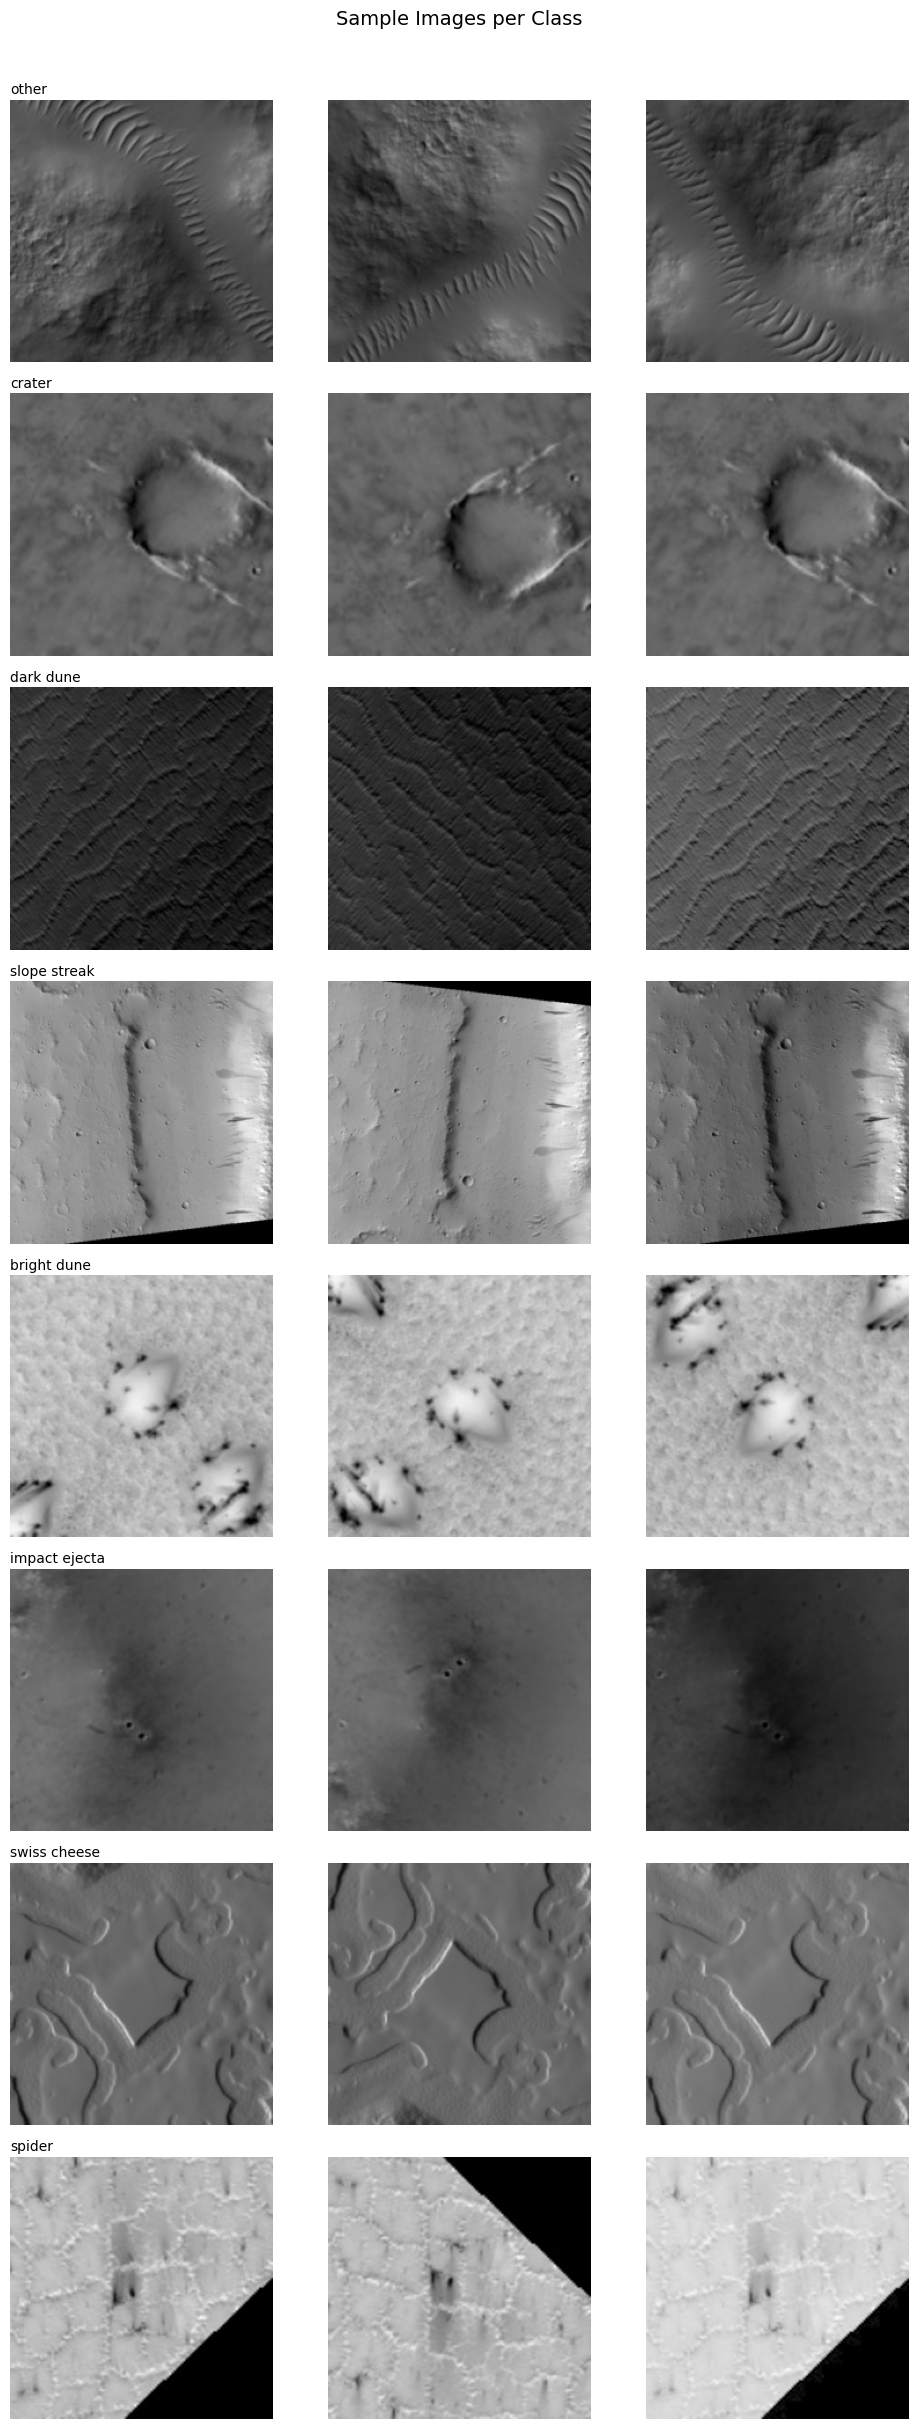

In [5]:
# Show sample images from each class
samples_per_class = 3
fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(10, 3 * num_classes))
fig.suptitle('Sample Images per Class', fontsize=14, y=1.01)

for class_idx, class_name in enumerate(class_names):
    # Get samples for this class from training set
    class_samples = train_df[train_df['label'] == class_idx].head(samples_per_class)
    
    for sample_idx, (_, row) in enumerate(class_samples.iterrows()):
        ax = axes[class_idx, sample_idx]
        img_path = find_image_path(row['filename'], dataset_dirs)
        
        if img_path and os.path.exists(img_path):
            img = Image.open(img_path).convert('RGB')
            ax.imshow(img)
        else:
            ax.set_facecolor('lightgray')
            ax.text(0.5, 0.5, 'N/A', ha='center', va='center', transform=ax.transAxes)
        
        ax.axis('off')
        if sample_idx == 0:
            ax.set_title(class_name, fontsize=10, loc='left', pad=4)

plt.tight_layout()
plt.show()
plt.close('all')

## 5. Class Distribution

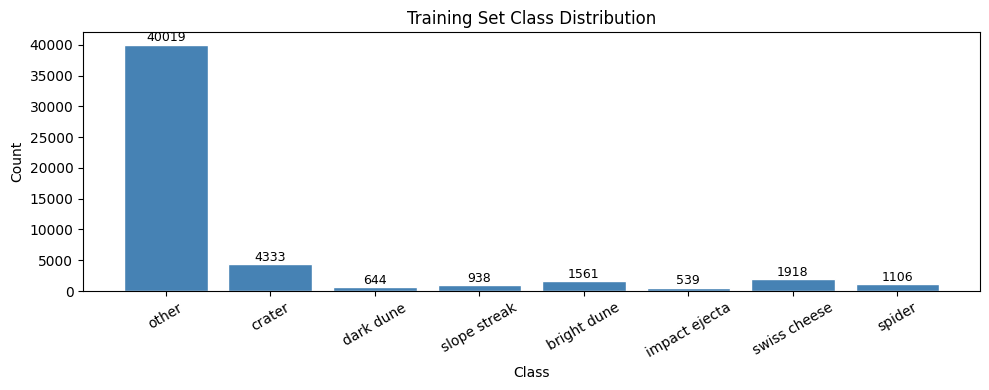

In [6]:
# Class distribution in training set
train_counts = train_df['label'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(class_names, train_counts.values, color='steelblue', edgecolor='white')
ax.set_xlabel('Class')
ax.set_ylabel('Count')
ax.set_title('Training Set Class Distribution')
ax.tick_params(axis='x', rotation=30)

for bar, count in zip(bars, train_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            str(count), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()
plt.close('all')

## 6. Calculate Class Weights

In [7]:
train_class_counts = np.bincount(train_df['label'].values, minlength=num_classes)
total_samples = len(train_df)
class_weights = total_samples / (num_classes * (train_class_counts + 1e-6))
class_weights = torch.FloatTensor(class_weights).to(device)

print('Class weights:')
for i, (name, weight) in enumerate(zip(class_names, class_weights.cpu().numpy())):
    print(f'  {name}: {weight:.4f}')

Class weights:
  other: 0.1595
  crater: 1.4729
  dark dune: 9.9103
  slope streak: 6.8041
  bright dune: 4.0886
  impact ejecta: 11.8409
  swiss cheese: 3.3276
  spider: 5.7706


## 7. Dataset Class

In [8]:
class MarsDataset(Dataset):
    def __init__(self, dataframe, dataset_dirs, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.dataset_dirs = dataset_dirs
        self.transform = transform
    
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]
        filename = row['filename']
        label = row['label']
        
        img_path = find_image_path(filename, self.dataset_dirs)
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        return image, label

print('Dataset class defined')

Dataset class defined


## 8. Data Transforms

In [9]:
mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

val_transform = transforms.Compose([
    transforms.Resize((image_size, image_size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

print('transforms defined')
print(f'image size: {image_size}x{image_size}')


transforms defined
image size: 224x224


## 9. DataLoaders

In [10]:
train_dataset = MarsDataset(train_df, dataset_dirs, transform=train_transform)
val_dataset   = MarsDataset(val_df,   dataset_dirs, transform=val_transform)
test_dataset  = MarsDataset(test_df,  dataset_dirs, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=2, pin_memory=True, persistent_workers=False)
val_loader   = DataLoader(val_dataset,   batch_size=batch_size, shuffle=False,
                          num_workers=2, pin_memory=True, persistent_workers=False)
test_loader  = DataLoader(test_dataset,  batch_size=batch_size, shuffle=False,
                          num_workers=2, pin_memory=True, persistent_workers=False)

print(f'train batches:      {len(train_loader)}')
print(f'validation batches: {len(val_loader)}')
print(f'test batches:       {len(test_loader)}')


train batches:      1596
validation batches: 468
test batches:       57


## 10. Load EfficientNet-B0 Model

In [11]:
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
print('loaded pretrained efficientnet-b0')

for param in model.features.parameters():
    param.requires_grad = False

in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, num_classes)

# single gpu — no dataparallel (avoids model duplication overhead)
model = model.to(device)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'total parameters:     {total_params:,}')
print(f'trainable parameters: {trainable_params:,}')


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 138MB/s]


loaded pretrained efficientnet-b0
total parameters:     4,017,796
trainable parameters: 10,248


## 11. Loss and Optimizer

In [12]:
criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimize only trainable parameters
optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=learning_rate,
    weight_decay=weight_decay
)

print('Loss function: CrossEntropyLoss with class weights')
print(f'Optimizer: Adam with lr={learning_rate}')

Loss function: CrossEntropyLoss with class weights
Optimizer: Adam with lr=0.001


## 12. Training and Validation Functions

In [13]:
from torch.cuda.amp import autocast, GradScaler

scaler = GradScaler()


def train_epoch(model, loader, criterion, optimizer, device, accumulation_steps=4):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    optimizer.zero_grad()

    for i, (images, labels) in enumerate(loader):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss = loss / accumulation_steps

        scaler.scale(loss).backward()

        if (i + 1) % accumulation_steps == 0 or (i + 1) == len(loader):
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        running_loss += loss.item() * accumulation_steps * images.size(0)
        _, predicted = outputs.max(1)
        total   += labels.size(0)
        correct += predicted.eq(labels).sum().item()

        del images, labels, outputs, loss

    return running_loss / total, correct / total


def validate_epoch(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total   += labels.size(0)
            correct += predicted.eq(labels).sum().item()

            del images, labels, outputs, loss

    return running_loss / total, correct / total


print('training functions defined (mixed precision + gradient accumulation)')


training functions defined (mixed precision + gradient accumulation)


/tmp/ipykernel_23/532691624.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()


## 13. Train Model

In [14]:
import gc

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_acc    = 0.0
patience_counter = 0

print(f'starting training for {num_epochs} epochs')
print(f'batch size: {batch_size}, accumulation steps: {accumulation_steps}')
print(f'effective batch size: {batch_size * accumulation_steps}')
start_time = time.time()

for epoch in range(num_epochs):
    epoch_start = time.time()

    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device, accumulation_steps)
    val_loss, val_acc     = validate_epoch(model, val_loader, criterion, device)

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    epoch_time = time.time() - epoch_start
    print(f'epoch [{epoch+1}/{num_epochs}] ({epoch_time:.1f}s)')
    print(f'  train loss: {train_loss:.4f}, acc: {train_acc:.4f}')
    print(f'  val loss:   {val_loss:.4f},   acc: {val_acc:.4f}')

    if val_acc > best_val_acc:
        best_val_acc     = val_acc
        patience_counter = 0
        torch.save(model.state_dict(), model_save_path)
        print(f'  model saved — val_acc: {val_acc:.4f}')
    else:
        patience_counter += 1
        print(f'  no improvement ({patience_counter}/{early_stopping_patience})')

    gc.collect()
    torch.cuda.empty_cache()

    if patience_counter >= early_stopping_patience:
        print(f'\nearly stopping after {epoch+1} epochs')
        break

total_time = time.time() - start_time
print(f'\ntraining completed in {total_time/60:.1f} minutes')
print(f'best validation accuracy: {best_val_acc:.4f}')


starting training for 50 epochs
batch size: 32, accumulation steps: 2
effective batch size: 64


/tmp/ipykernel_23/532691624.py:18: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():
/tmp/ipykernel_23/532691624.py:51: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


epoch [1/50] (304.2s)
  train loss: 0.6708, acc: 0.7021
  val loss:   1.2175,   acc: 0.4975
  model saved — val_acc: 0.4975
epoch [2/50] (222.2s)
  train loss: 0.4228, acc: 0.7549
  val loss:   0.9550,   acc: 0.6462
  model saved — val_acc: 0.6462
epoch [3/50] (220.9s)
  train loss: 0.3865, acc: 0.7604
  val loss:   0.9388,   acc: 0.6269
  no improvement (1/15)
epoch [4/50] (225.3s)
  train loss: 0.3501, acc: 0.7602
  val loss:   0.9093,   acc: 0.6651
  model saved — val_acc: 0.6651
epoch [5/50] (224.6s)
  train loss: 0.3363, acc: 0.7754
  val loss:   0.8659,   acc: 0.6958
  model saved — val_acc: 0.6958
epoch [6/50] (221.9s)
  train loss: 0.3273, acc: 0.7740
  val loss:   0.9062,   acc: 0.6543
  no improvement (1/15)
epoch [7/50] (220.6s)
  train loss: 0.3282, acc: 0.7723
  val loss:   0.8449,   acc: 0.7059
  model saved — val_acc: 0.7059
epoch [8/50] (225.5s)
  train loss: 0.3342, acc: 0.7772
  val loss:   0.9955,   acc: 0.6149
  no improvement (1/15)
epoch [9/50] (228.2s)
  train lo

## 14. Training History

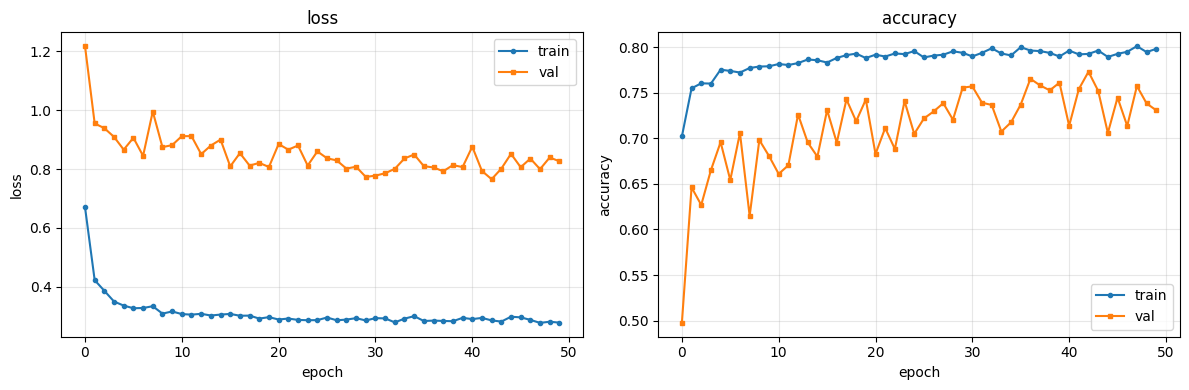

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history['train_loss'], label='train', marker='o', markersize=3)
ax1.plot(history['val_loss'],   label='val',   marker='s', markersize=3)
ax1.set_xlabel('epoch')
ax1.set_ylabel('loss')
ax1.set_title('loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(history['train_acc'], label='train', marker='o', markersize=3)
ax2.plot(history['val_acc'],   label='val',   marker='s', markersize=3)
ax2.set_xlabel('epoch')
ax2.set_ylabel('accuracy')
ax2.set_title('accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
plt.close('all')


## 15. Test Evaluation

## 13b. Save Inference Metadata

In [16]:
import json

inference_config = {
    'class_names': class_names,
    'image_size': image_size,
    'mean': mean,
    'std': std,
    'num_classes': num_classes
}
with open(inference_config_path, 'w') as f:
    json.dump(inference_config, f, indent=2)

print(f'inference config saved to {inference_config_path}')


inference config saved to efficientnet_inference_config.json


In [17]:
model.load_state_dict(torch.load(model_save_path, weights_only=True))
model.eval()

all_predictions = []
all_labels      = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)

        with autocast():
            outputs = model(images)

        _, predicted = outputs.max(1)
        all_predictions.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

        del images, outputs

all_predictions = np.array(all_predictions)
all_labels      = np.array(all_labels)

print(f'test evaluation completed — {len(all_labels)} samples')


/tmp/ipykernel_23/760952071.py:11: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


test evaluation completed — 1793 samples


## 16. Metrics

In [18]:
test_accuracy = accuracy_score(all_labels, all_predictions)
test_precision = precision_score(all_labels, all_predictions, average='weighted', zero_division=0)
test_recall = recall_score(all_labels, all_predictions, average='weighted', zero_division=0)
test_f1 = f1_score(all_labels, all_predictions, average='weighted', zero_division=0)

print('Test Set Performance:')
print(f'Accuracy:  {test_accuracy:.4f}')
print(f'Precision: {test_precision:.4f}')
print(f'Recall:    {test_recall:.4f}')
print(f'F1-Score:  {test_f1:.4f}')

Test Set Performance:
Accuracy:  0.8031
Precision: 0.8811
Recall:    0.8031
F1-Score:  0.8318


## 17. Classification Report

In [19]:
print('Classification Report:')
print(classification_report(all_labels, all_predictions, target_names=class_names, zero_division=0))

Classification Report:
               precision    recall  f1-score   support

        other       0.96      0.82      0.89      1482
       crater       0.43      0.67      0.53        89
    dark dune       0.78      0.85      0.81        66
 slope streak       0.33      0.76      0.46        49
  bright dune       0.37      0.94      0.53        16
impact ejecta       0.05      0.57      0.10         7
 swiss cheese       0.79      0.98      0.87        42
       spider       0.26      0.21      0.23        42

     accuracy                           0.80      1793
    macro avg       0.50      0.72      0.55      1793
 weighted avg       0.88      0.80      0.83      1793



## 18. Confusion Matrix

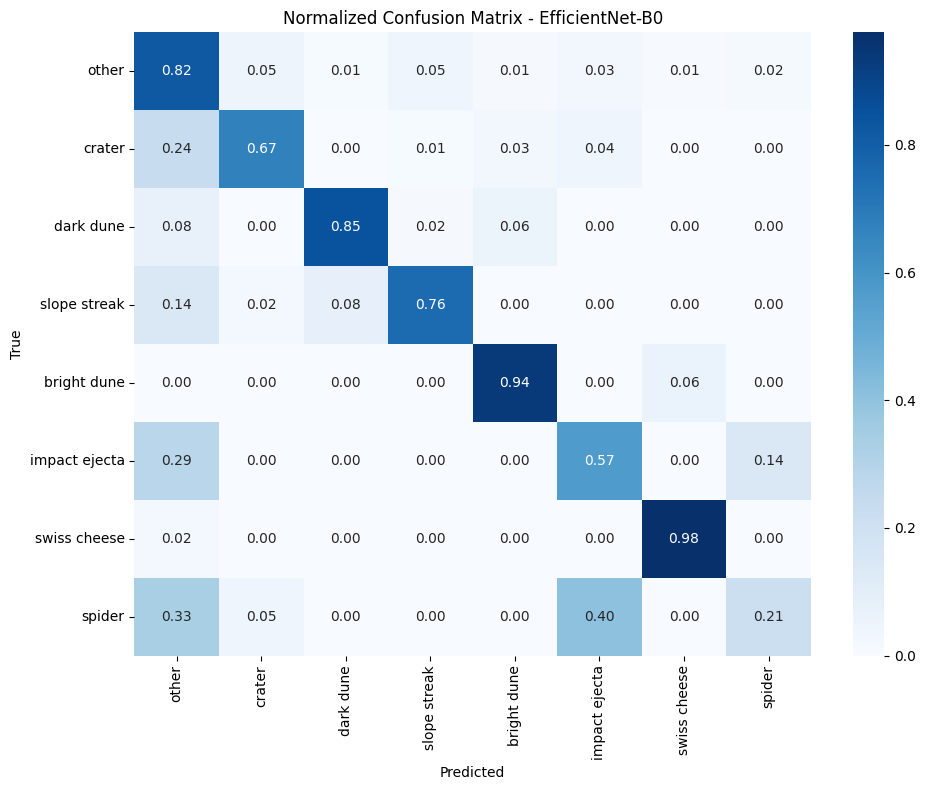

In [20]:
cm = confusion_matrix(all_labels, all_predictions)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(10, 8))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Normalized Confusion Matrix - EfficientNet-B0')
plt.tight_layout()
plt.show()
plt.close('all')

## 19. Per-Class Performance

In [21]:
per_class_precision = precision_score(all_labels, all_predictions, average=None, zero_division=0)
per_class_recall = recall_score(all_labels, all_predictions, average=None, zero_division=0)
per_class_f1 = f1_score(all_labels, all_predictions, average=None, zero_division=0)

print('Per-Class Performance:')
for i, name in enumerate(class_names):
    print(f'{name}:')
    print(f'  Precision: {per_class_precision[i]:.4f}')
    print(f'  Recall:    {per_class_recall[i]:.4f}')
    print(f'  F1-Score:  {per_class_f1[i]:.4f}')

Per-Class Performance:
other:
  Precision: 0.9606
  Recall:    0.8219
  F1-Score:  0.8858
crater:
  Precision: 0.4317
  Recall:    0.6742
  F1-Score:  0.5263
dark dune:
  Precision: 0.7778
  Recall:    0.8485
  F1-Score:  0.8116
slope streak:
  Precision: 0.3333
  Recall:    0.7551
  F1-Score:  0.4625
bright dune:
  Precision: 0.3659
  Recall:    0.9375
  F1-Score:  0.5263
impact ejecta:
  Precision: 0.0533
  Recall:    0.5714
  F1-Score:  0.0976
swiss cheese:
  Precision: 0.7885
  Recall:    0.9762
  F1-Score:  0.8723
spider:
  Precision: 0.2571
  Recall:    0.2143
  F1-Score:  0.2338


## 20. Per-Class F1 Bar Chart

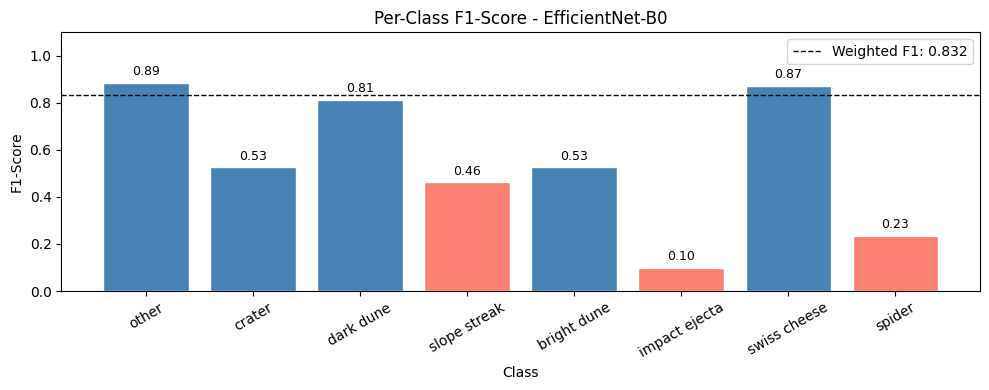

In [22]:
fig, ax = plt.subplots(figsize=(10, 4))
colors = ['steelblue' if f1 >= 0.5 else 'salmon' for f1 in per_class_f1]
bars = ax.bar(class_names, per_class_f1, color=colors, edgecolor='white')
ax.axhline(y=test_f1, color='black', linestyle='--', linewidth=1, label=f'Weighted F1: {test_f1:.3f}')
ax.set_xlabel('Class')
ax.set_ylabel('F1-Score')
ax.set_title('Per-Class F1-Score - EfficientNet-B0')
ax.set_ylim(0, 1.1)
ax.tick_params(axis='x', rotation=30)
ax.legend()

for bar, f1 in zip(bars, per_class_f1):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
            f'{f1:.2f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()
plt.close('all')

## 21. Summary

In [23]:
print('Model Training Summary')
print(f'Architecture: EfficientNet-B0 with transfer learning')
print(f'Total parameters: {total_params:,}')
print(f'Trainable parameters: {trainable_params:,}')
print(f'\nTraining configuration:')
print(f'  Image size: {image_size}x{image_size}')
print(f'  Batch size: {batch_size}')
print(f'  Epochs: {num_epochs}')
print(f'  Learning rate: {learning_rate}')
print(f'\nDataset splits:')
print(f'  Training: {len(train_df)} samples')
print(f'  Validation: {len(val_df)} samples')
print(f'  Test: {len(test_df)} samples')
print(f'\nBest validation accuracy: {best_val_acc:.4f}')
print(f'\nTest set performance:')
print(f'  Accuracy:  {test_accuracy:.4f}')
print(f'  Precision: {test_precision:.4f}')
print(f'  Recall:    {test_recall:.4f}')
print(f'  F1-Score:  {test_f1:.4f}')

Model Training Summary
Architecture: EfficientNet-B0 with transfer learning
Total parameters: 4,017,796
Trainable parameters: 10,248

Training configuration:
  Image size: 224x224
  Batch size: 32
  Epochs: 50
  Learning rate: 0.001

Dataset splits:
  Training: 51058 samples
  Validation: 14959 samples
  Test: 1793 samples

Best validation accuracy: 0.7732

Test set performance:
  Accuracy:  0.8031
  Precision: 0.8811
  Recall:    0.8031
  F1-Score:  0.8318
